# 🏛️ ĐỒ ÁN DAT301m: DATA-CENTRIC AI — CHỮ SỐ LA MÃ
## Thực nghiệm với VGG16 tự xây dựng từ đầu

**Nhóm thực hiện:** Team 1 (Tuấn, Chiến, Trà, Huy, Duy).

Notebook gồm **6 stage huấn luyện, đánh số từ Stage 0 đến Stage 5**: Baseline, làm sạch, chuẩn hóa hình học, cân bằng 7.500 ảnh, mở rộng 9.500 ảnh và Superior với mục tiêu 9.900 ảnh. **Phần 6 là đánh giá tổng hợp, không phải stage huấn luyện thứ bảy.**

Notebook khảo sát các bước làm sạch, chuẩn hóa và tăng cường dữ liệu khi giữ cùng hàm xây dựng mô hình VGG16 scratch và optimizer Adam. Stage 4 và Superior sử dụng thêm callback chọn checkpoint/dừng sớm; vì vậy không diễn giải đây là thí nghiệm chỉ thay đổi dữ liệu trong mọi điều kiện.

**Kết quả đã lưu:** cả 6 stage đều có output huấn luyện và đánh giá. Baseline đạt **63.96% validation / 59.62% Label Book**. Stage 4 có validation accuracy cao nhất: **91.42%**. Stage 3, Stage 4 và Superior cùng đạt Label Book Accuracy **84.62% (44/52 ảnh)**; Superior có Label Book Loss thấp nhất trong 6 stage: **0.4323**.

| Stage | Validation Accuracy | Validation Loss | Label Book Accuracy | Label Book Loss |
|---|---:|---:|---:|---:|
| 0 — Baseline | 63.96% | 0.9633 | 59.62% | 1.4736 |
| 1 — Làm sạch | 53.81% | 1.4332 | 55.77% | 1.4091 |
| 2 — Chuẩn hóa hình học | 82.65% | 0.7222 | 76.92% | 0.8010 |
| 3 — Cân bằng 7.500 ảnh | 90.87% | 0.4356 | 84.62% | 0.9228 |
| 4 — Mở rộng 9.500 ảnh | 91.42% | 0.4100 | 84.62% | 0.8788 |
| 5 — Superior | 86.02% | 0.6391 | 84.62% | 0.4323 |

Các số liệu lấy từ phần **đánh giá sau huấn luyện** của từng stage trong file hiện tại. Stage 0–3 đánh giá trọng số cuối; Stage 4 khôi phục epoch 14, Superior khôi phục epoch 7 theo validation accuracy. Các lần chạy có thể cho kết quả khác nhau.

`label_book` có 52 ảnh, là tập đánh giá tham chiếu; không gọi đây là kết quả trên test ẩn của cuộc thi. Validation giữa các stage có cách tạo khác nhau, nên các điểm số không phải phép so sánh trên một tập validation cố định.

### Mục lục
1. [Khởi tạo mô hình](#setup)
2. [Stage 0: Baseline và kiểm tra dữ liệu](#stage0)
3. [Stage 1: Làm sạch](#stage1)
4. [Stage 2: Chuẩn hóa hình học](#stage2)
5. [Stage 3: Cân bằng 7.500 ảnh](#stage3)
6. [Stage 4: Mở rộng 9.500 ảnh](#stage4)
7. [Stage 5: Superior](#stage5_superior)
8. [Đánh giá tổng hợp](#stage6_eval)


In [1]:
import sys
import os

try:
    import google.colab
    IN_COLAB = True
    print("🚀 Đang chạy trên Google Colab")
except ImportError:
    IN_COLAB = False
    print("💻 Đang chạy trên Local Machine")

if IN_COLAB:
    if os.path.exists("/content/deeplearningai-data-centric-competition"):
        os.chdir("/content/deeplearningai-data-centric-competition")
    elif not os.path.exists("data"):
        os.system("git clone https://github.com/Nov05/deeplearningai-data-centric-competition.git")
        if os.path.exists("deeplearningai-data-centric-competition"):
            os.chdir("deeplearningai-data-centric-competition")

# Giải nén data và label_book nếu chưa có
import tarfile
if not os.path.exists("data") and os.path.exists("original/data.tar.gz"):
    with tarfile.open("original/data.tar.gz", "r:gz") as tar:
        tar.extractall(".")
    print("✅ Đã giải nén dữ liệu data thành công.")

if not os.path.exists("label_book") and os.path.exists("original/label_book.tar.gz"):
    with tarfile.open("original/label_book.tar.gz", "r:gz") as tar:
        tar.extractall(".")
    print("✅ Đã giải nén dữ liệu label_book thành công.")

import glob
raw_count = len(glob.glob("data/**/*.png", recursive=True))
print(f"✅ Dữ liệu gốc: Tìm thấy {raw_count} ảnh.")
assert raw_count > 0, "LỖI: Chưa có ảnh trong thư mục 'data/'!"


🚀 Đang chạy trên Google Colab
✅ Dữ liệu gốc: Tìm thấy 2880 ảnh.


<a id="setup"></a>
## 1. KHỞI TẠO VGG16 SCRATCH

Kiến trúc được viết bằng các lớp Keras: 13 Conv2D, 5 MaxPooling2D và 3 Dense. Không dùng `keras.applications.VGG16` hoặc pretrained weights. Ảnh đầu vào 32 × 32 RGB; mô hình chia giá trị pixel cho 255. Adam có learning rate 1e-4, batch size 32, tối đa 15 epoch mỗi stage.
Output môi trường ghi nhận TensorFlow **2.21.0**, GPU `/physical_device:GPU:0` và thông báo mô hình có **15.245.130 tham số**.


In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import hashlib
import shutil
from PIL import Image

IMAGE_SIZE = (32, 32)
BATCH_SIZE = 32
NUM_CLASSES = 10
CLASS_NAMES = ["i", "ii", "iii", "iv", "v", "vi", "vii", "viii", "ix", "x"]
RANDOM_SEED = 123
EPOCHS = 15

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"🚀 Thiết bị tăng tốc: ĐÃ BẬT GPU ({gpus[0].name}) -> Tốc độ huấn luyện cực nhanh!")
else:
    print("⚠️ Thiết bị hiện tại: CPU (Khuyên dùng: Trên Colab vào Menu Runtime -> Change runtime type -> Chọn T4 GPU)")

def build_fixed_vgg16_model():
    """
    KIẾN TRÚC VGG16 TỰ XÂY DỰNG TỪ ĐẦU (FROM SCRATCH) THEO YÊU CẦU GIẢNG VIÊN:
    - KHÔNG dùng thư viện có sẵn tf.keras.applications.VGG16
    - KHÔNG dùng pretrained weights ImageNet
    - Tự code tay đúng 13 lớp Conv2D + 5 lớp MaxPooling2D + 3 lớp Dense = 16 Layers VGG16
    - Khởi tạo He-Normal, cố định bất biến qua mọi Stage
    """
    tf.random.set_seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)

    inputs = tf.keras.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3), name="input_image")
    x = tf.keras.layers.Rescaling(1.0 / 255.0, name="rescaling")(inputs)

    # Block 1 (2 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b1_c1")(x)
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b1_c2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b1_pool")(x)

    # Block 2 (2 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b2_c1")(x)
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b2_c2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b2_pool")(x)

    # Block 3 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c1")(x)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c2")(x)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b3_pool")(x)

    # Block 4 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c1")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c2")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b4_pool")(x)

    # Block 5 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c1")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c2")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b5_pool")(x)

    # Classifier Head (13 Conv + 3 Dense = 16 Layers VGG16)
    x = tf.keras.layers.Flatten(name="flatten")(x)
    x = tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal", name="fc1")(x)
    x = tf.keras.layers.Dropout(0.5, name="dropout1")(x)
    x = tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal", name="fc2")(x)
    x = tf.keras.layers.Dropout(0.5, name="dropout2")(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Fixed_VGG16_Scratch")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("✅ Đã khởi tạo cấu trúc Fixed VGG16 Scratch thành công (15.245.130 tham số).")


TensorFlow Version: 2.21.0
🚀 Thiết bị tăng tốc: ĐÃ BẬT GPU (/physical_device:GPU:0) -> Tốc độ huấn luyện cực nhanh!
✅ Đã khởi tạo cấu trúc Fixed VGG16 Scratch thành công (15.245.130 tham số).


<a id="stage0"></a>
## 2. NẠP DỮ LIỆU GỐC

Output ghi nhận **2.067 ảnh train, 813 ảnh validation và 52 ảnh Label Book**, thuộc 10 lớp. Stage 0 dùng cách chia gốc của cuộc thi. Các bước sau ghi ảnh xử lý vào thư mục riêng, không sửa ảnh trong `data/train`, `data/val` hoặc `label_book`.
Tổng ảnh gốc là **2.880**; số batch được in là **65 train / 26 validation**.


In [3]:
train_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    "data/train", labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=True, seed=RANDOM_SEED,
    batch_size=BATCH_SIZE, image_size=IMAGE_SIZE
)

val_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    "data/val", labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False, seed=RANDOM_SEED,
    batch_size=BATCH_SIZE, image_size=IMAGE_SIZE
)

lb_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    "label_book", labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False,
    batch_size=BATCH_SIZE, image_size=IMAGE_SIZE
)

print(f"Số batch Train: {train_ds_raw.cardinality().numpy()} | Val: {val_ds_raw.cardinality().numpy()}")


Found 2067 files belonging to 10 classes.
Found 813 files belonging to 10 classes.
Found 52 files belonging to 10 classes.
Số batch Train: 65 | Val: 26


## 3. HUẤN LUYỆN BASELINE TRONG 15 EPOCH

**Kết quả lưu trong notebook:** Validation Accuracy **63.96%** (loss 0.9633); Label Book Accuracy **59.62%** (loss 1.4736).


In [4]:
baseline_model = build_fixed_vgg16_model()

history_s0 = baseline_model.fit(
    train_ds_raw,
    validation_data=val_ds_raw,
    epochs=EPOCHS,
    verbose=1
)

val_loss_s0, val_acc_s0 = baseline_model.evaluate(val_ds_raw, verbose=0)
lb_loss_s0, lb_acc_s0 = baseline_model.evaluate(lb_ds_raw, verbose=0)

print("="*60)
print(f"📊 KẾT QUẢ STAGE 0 (BASELINE):")
print(f"  • Validation Accuracy (Nội bộ): {val_acc_s0*100:.2f}% | Loss: {val_loss_s0:.4f}")
print(f"  • Label Book Accuracy (Test độc lập): {lb_acc_s0*100:.2f}% | Loss: {lb_loss_s0:.4f}")
print("="*60)


Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 82s 627ms/step - accuracy: 0.1108 - loss: 2.3490 - val_accuracy: 0.1033 - val_loss: 2.3049
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.1311 - loss: 2.2959 - val_accuracy: 0.1033 - val_loss: 2.3065
Epoch 3/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.1239 - loss: 2.2937 - val_accuracy: 0.1033 - val_loss: 2.3055
Epoch 4/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.1451 - loss: 2.2898 - val_accuracy: 0.1513 - val_loss: 2.2834
Epoch 5/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.1916 - loss: 2.2163 - val_accuracy: 0.2128 - val_loss: 2.0124
Epoch 6/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.2496 - loss: 2.0240 - val_accuracy: 0.2755 - val_loss: 1.8046
Epoch 7/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.2970 - loss: 1.8637 - val_accuracy: 0.3050 - val_loss: 1.7648
Epoch 8/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.3633 - loss: 1.6924 - val_accuracy: 0.3690 -

## 4. KIỂM TRA TRÙNG LẶP VÀ ẢNH TRẮNG

Output của cell kiểm tra ghi nhận **49 ảnh trong validation có MD5 trùng với ảnh train** và một ảnh trắng `data/train/vi/aac26b40-ce5d-11eb-b317-38f9d35ea60f.png`. Cell này không định lượng ảnh lệch tâm, phân bố kích thước nét chữ hoặc tỷ lệ sai nhãn.


In [5]:
# 1. Quét rò rỉ dữ liệu qua MD5
train_hashes = {}
for f in glob.glob("data/train/*/*.png"):
    with open(f, "rb") as fp:
        train_hashes[hashlib.md5(fp.read()).hexdigest()] = f

leakage_count = 0
for f in glob.glob("data/val/*/*.png"):
    with open(f, "rb") as fp:
        h = hashlib.md5(fp.read()).hexdigest()
        if h in train_hashes:
            leakage_count += 1
print(f"⚠️ Phát hiện {leakage_count} ảnh trùng lặp 100% giữa Train và Validation (Data Leakage)!")

# 2. Quét ảnh trắng tinh
blank_count = 0
for f in glob.glob("data/*/*/*.png"):
    arr = np.array(Image.open(f).convert("L"))
    if arr.min() == 255:
        print(f"⚠️ Phát hiện ảnh trắng xóa: {f}")
        blank_count += 1


⚠️ Phát hiện 49 ảnh trùng lặp 100% giữa Train và Validation (Data Leakage)!
⚠️ Phát hiện ảnh trắng xóa: data/train/vi/aac26b40-ce5d-11eb-b317-38f9d35ea60f.png


<a id="stage1"></a>
# STAGE 1: LÀM SẠCH DỮ LIỆU

Gộp ảnh gốc từ train và validation, bỏ các tên file trong danh sách loại trừ, khử bản sao theo MD5 và bỏ ảnh trắng. Ảnh được sao chép vào `stage1_cleaned_data`; dữ liệu gốc được giữ nguyên.

Output ghi nhận **2.825 ảnh**, chia thành **2.260 train / 565 validation** bằng `validation_split=0.2` và cùng seed. Đây là phép chia ngẫu nhiên của Keras, **không phải stratified split theo lớp**. Danh sách tên file loại trừ là quy tắc đã khai báo trong code, không phải kết quả tự động phát hiện sai nhãn của cell kiểm tra.


## 1. TẠO TẬP DỮ LIỆU LÀM SẠCH


In [6]:
CLEAN_STAGE1_DIR = "stage1_cleaned_data"
if os.path.exists(CLEAN_STAGE1_DIR):
    shutil.rmtree(CLEAN_STAGE1_DIR)
os.makedirs(CLEAN_STAGE1_DIR, exist_ok=True)

KNOWN_CORRUPT_OR_MISLABELED_FILES = {
    "aac26b40-ce5d-11eb-b317-38f9d35ea60f.png", # Ảnh trắng tinh 100%
    "b0a13faa-ce5d-11eb-b317-38f9d35ea60f.png", # Chữ X nhưng gán vào iii
    "b030ba5a-ce5d-11eb-b317-38f9d35ea60f.png", # Chỉ 1 gạch dọc I nhưng gán vào iii
    "aec401ea-ce5d-11eb-b317-38f9d35ea60f.png", # Chữ VI nhưng gán vào ix
    "aec04e56-ce5d-11eb-b317-38f9d35ea60f.png", # Chữ VI nhưng gán vào ix
    "adf5ad04-ce5d-11eb-b317-38f9d35ea60f.png"  # Nét loang mực lỗi gán vào iv
}

seen_hashes = set()
total_cleaned = 0

for c in CLASS_NAMES:
    c_dest = os.path.join(CLEAN_STAGE1_DIR, c)
    os.makedirs(c_dest, exist_ok=True)
    raw_files = glob.glob(f"data/train/{c}/*.png") + glob.glob(f"data/val/{c}/*.png")

    for f in raw_files:
        fname = os.path.basename(f)
        if fname in KNOWN_CORRUPT_OR_MISLABELED_FILES:
            continue
        with open(f, "rb") as fp:
            h = hashlib.md5(fp.read()).hexdigest()
            if h in seen_hashes:
                continue
            seen_hashes.add(h)
        arr = np.array(Image.open(f).convert("L"))
        if arr.min() == 255:
            continue

        shutil.copy(f, os.path.join(c_dest, fname))
        total_cleaned += 1

print(f"✅ Đã làm sạch toàn bộ dữ liệu. Tổng số ảnh sạch: {total_cleaned} ảnh.")


✅ Đã làm sạch toàn bộ dữ liệu. Tổng số ảnh sạch: 2825 ảnh.


## 2. CHIA 80/20 VÀ HUẤN LUYỆN LẠI

**Kết quả lưu trong notebook:** Validation Accuracy **53.81%** (loss 1.4332); Label Book Accuracy **55.77%** (loss 1.4091).


In [7]:
train_ds_s1 = tf.keras.preprocessing.image_dataset_from_directory(
    CLEAN_STAGE1_DIR, validation_split=0.2, subset="training",
    seed=RANDOM_SEED, labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

val_ds_s1 = tf.keras.preprocessing.image_dataset_from_directory(
    CLEAN_STAGE1_DIR, validation_split=0.2, subset="validation",
    seed=RANDOM_SEED, labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

lb_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    "label_book", labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False,
    batch_size=BATCH_SIZE, image_size=IMAGE_SIZE
)

model_s1 = build_fixed_vgg16_model()
history_s1 = model_s1.fit(
    train_ds_s1,
    validation_data=val_ds_s1,
    epochs=EPOCHS,
    verbose=1
)

val_loss_s1, val_acc_s1 = model_s1.evaluate(val_ds_s1, verbose=0)
lb_loss_s1, lb_acc_s1 = model_s1.evaluate(lb_ds_raw, verbose=0)

print("="*60)
print(f"📊 KẾT QUẢ STAGE 1 (DATA CLEANING):")
print(f"  • Validation Accuracy (Sạch không rò rỉ): {val_acc_s1*100:.2f}% | Loss: {val_loss_s1:.4f}")
print(f"  • Label Book Accuracy: {lb_acc_s1*100:.2f}% | Loss: {lb_loss_s1:.4f}")
print("="*60)


Found 2825 files belonging to 10 classes.
Using 2260 files for training.
Found 2825 files belonging to 10 classes.
Using 565 files for validation.
Found 52 files belonging to 10 classes.
Epoch 1/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 34s 374ms/step - accuracy: 0.1088 - loss: 2.3307 - val_accuracy: 0.1257 - val_loss: 2.2966
Epoch 2/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.1221 - loss: 2.3002 - val_accuracy: 0.1257 - val_loss: 2.2951
Epoch 3/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.1407 - loss: 2.2745 - val_accuracy: 0.2035 - val_loss: 2.1719
Epoch 4/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.2088 - loss: 2.1039 - val_accuracy: 0.2708 - val_loss: 1.8697
Epoch 5/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.2991 - loss: 1.8683 - val_accuracy: 0.2885 - val_loss: 1.7567
Epoch 6/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.3301 - loss: 1.7340 - val_accuracy: 0.3345 - val_loss: 1.6504
Epoch 7/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/ste

<a id="stage2"></a>
# STAGE 2: CHUẨN HÓA HÌNH HỌC VÀ NỀN

Chuyển ảnh sang grayscale, đưa pixel > 215 về trắng, tìm bounding box của nét chữ, căn giữa trên canvas vuông có padding 15%, tăng tương phản nét tối rồi resize về 32 × 32 bằng bilinear. Label Book được xử lý bằng cùng hàm.

Stage này đọc lại `data/train` và `data/val`, bỏ hai tên file và khử MD5 trong từng lớp; không đọc trực tiếp tập 2.825 ảnh của Stage 1. Output ghi nhận **2.829 ảnh**, chia **2.264 train / 565 validation**. Vì bộ lọc và phép chia khác Stage 1, chênh lệch accuracy không thể quy hoàn toàn cho chuẩn hóa hình học.


In [8]:
def preprocess_and_center_numeral(img_pil, target_size=(32, 32), pad_ratio=0.15):
    gray = img_pil.convert("L")
    arr = np.array(gray)
    arr[arr > 215] = 255 # Tẩy trắng nền scan
    ys, xs = np.where(arr < 215)
    if len(ys) == 0:
        return None
    ymin, ymax = ys.min(), ys.max()
    xmin, xmax = xs.min(), xs.max()
    h = ymax - ymin + 1
    w = xmax - xmin + 1
    max_dim = max(h, w)
    pad = int(max_dim * pad_ratio)
    total_size = max_dim + 2 * pad
    canvas = np.ones((total_size, total_size), dtype=np.uint8) * 255
    crop = arr[ymin:ymax+1, xmin:xmax+1]
    canvas[(total_size-h)//2:(total_size-h)//2+h, (total_size-w)//2:(total_size-w)//2+w] = crop
    canvas[canvas < 120] = (canvas[canvas < 120] * 0.7).astype(np.uint8) # Boost tương phản
    res = Image.fromarray(canvas).resize(target_size, Image.Resampling.BILINEAR)
    return res.convert("RGB")

def ensure_clean_label_book():
    CLEAN_LB_DIR = "clean_label_book"
    if not os.path.exists(CLEAN_LB_DIR) or len(glob.glob(f"{CLEAN_LB_DIR}/*/*.png")) == 0:
        os.makedirs(CLEAN_LB_DIR, exist_ok=True)
        for c in CLASS_NAMES:
            os.makedirs(os.path.join(CLEAN_LB_DIR, c), exist_ok=True)
            for f in glob.glob(f"label_book/{c}/*.png"):
                proc = preprocess_and_center_numeral(Image.open(f), target_size=IMAGE_SIZE)
                if proc is not None:
                    proc.save(os.path.join(CLEAN_LB_DIR, c, os.path.basename(f)))
        print("✅ Đã tự động khởi tạo clean_label_book chuẩn hóa.")


## 1. TẠO `stage2_geometric_data` VÀ LABEL BOOK CHUẨN HÓA


In [9]:
STAGE2_DIR = "stage2_geometric_data"
if os.path.exists(STAGE2_DIR):
    shutil.rmtree(STAGE2_DIR)
os.makedirs(STAGE2_DIR, exist_ok=True)

ensure_clean_label_book()

for c in CLASS_NAMES:
    c_dest = os.path.join(STAGE2_DIR, c)
    os.makedirs(c_dest, exist_ok=True)
    raw_files = glob.glob(f"data/train/{c}/*.png") + glob.glob(f"data/val/{c}/*.png")
    seen_hashes = set()
    idx = 0
    for f in raw_files:
        if os.path.basename(f) in {"aac26b40-ce5d-11eb-b317-38f9d35ea60f.png", "b0a13faa-ce5d-11eb-b317-38f9d35ea60f.png"}:
            continue
        with open(f, "rb") as fp:
            h = hashlib.md5(fp.read()).hexdigest()
            if h in seen_hashes:
                continue
            seen_hashes.add(h)
        proc = preprocess_and_center_numeral(Image.open(f), target_size=IMAGE_SIZE)
        if proc is not None:
            proc.save(os.path.join(c_dest, f"geo_{idx}.png"))
            idx += 1

print(f"✅ Đã chuẩn hóa toàn bộ hình học ảnh. Số ảnh: {len(glob.glob(f'{STAGE2_DIR}/*/*.png'))}")


✅ Đã chuẩn hóa toàn bộ hình học ảnh. Số ảnh: 2829


## 2. HUẤN LUYỆN TRÊN DỮ LIỆU CHUẨN HÓA

**Kết quả lưu trong notebook:** Validation Accuracy **82.65%** (loss 0.7222); Label Book Accuracy **76.92%** (loss 0.8010).


In [10]:
train_ds_s2 = tf.keras.preprocessing.image_dataset_from_directory(
    STAGE2_DIR, validation_split=0.2, subset="training", seed=RANDOM_SEED,
    labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

val_ds_s2 = tf.keras.preprocessing.image_dataset_from_directory(
    STAGE2_DIR, validation_split=0.2, subset="validation", seed=RANDOM_SEED,
    labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

clean_lb_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "clean_label_book", labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False,
    batch_size=BATCH_SIZE, image_size=IMAGE_SIZE
)

model_s2 = build_fixed_vgg16_model()
history_s2 = model_s2.fit(train_ds_s2, validation_data=val_ds_s2, epochs=EPOCHS, verbose=1)

val_loss_s2, val_acc_s2 = model_s2.evaluate(val_ds_s2, verbose=0)
lb_loss_s2, lb_acc_s2 = model_s2.evaluate(clean_lb_ds, verbose=0)

print("="*60)
print(f"📊 KẾT QUẢ STAGE 2 (GEOMETRIC & BACKGROUND WHITENING):")
print(f"  • Validation Accuracy: {val_acc_s2*100:.2f}% | Loss: {val_loss_s2:.4f}")
print(f"  • Label Book Accuracy: {lb_acc_s2*100:.2f}% | Loss: {lb_loss_s2:.4f}")
print("="*60)


Found 2829 files belonging to 10 classes.
Using 2264 files for training.
Found 2829 files belonging to 10 classes.
Using 565 files for validation.
Found 52 files belonging to 10 classes.
Epoch 1/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 30s 310ms/step - accuracy: 0.1047 - loss: 2.3534 - val_accuracy: 0.1239 - val_loss: 2.2928
Epoch 2/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.1223 - loss: 2.2974 - val_accuracy: 0.1204 - val_loss: 2.2872
Epoch 3/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.1696 - loss: 2.2355 - val_accuracy: 0.1912 - val_loss: 2.0878
Epoch 4/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.2694 - loss: 1.9520 - val_accuracy: 0.4124 - val_loss: 1.6352
Epoch 5/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.3538 - loss: 1.6829 - val_accuracy: 0.4496 - val_loss: 1.3497
Epoch 6/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.4682 - loss: 1.4125 - val_accuracy: 0.6549 - val_loss: 1.1012
Epoch 7/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/st

<a id="stage3"></a>
# STAGE 3: CÂN BẰNG LỚP VÀ AUGMENTATION

Dùng ảnh trong `stage2_geometric_data` làm nguồn; giữ ảnh nguồn và sinh thêm đến **750 ảnh/lớp**, tổng **7.500 ảnh**. Augmentation gồm xoay ±8°, dịch ngang/dọc tối đa 8% và zoom 8%; không lật ngang để hạn chế làm thay đổi ý nghĩa ký tự.

Output nạp dữ liệu ghi nhận **6.000 train / 1.500 validation**. Việc chia diễn ra **sau augmentation**, nên các biến thể của cùng ảnh gốc có thể xuất hiện ở cả hai tập. Validation này không bảo đảm độc lập ở cấp ảnh nguồn. Classification report ở Phần 6 thuộc Stage 4, nên không dùng để suy ra recall từng lớp của Stage 3.


## 1. TẠO TẬP CÂN BẰNG 7.500 ẢNH


In [11]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

STAGE3_DIR = "stage3_balanced_data"
if os.path.exists(STAGE3_DIR):
    shutil.rmtree(STAGE3_DIR)
os.makedirs(STAGE3_DIR, exist_ok=True)

ensure_clean_label_book()

# Đảm bảo có dữ liệu sạch đã căn giữa
if not os.path.exists("stage2_geometric_data") or len(glob.glob("stage2_geometric_data/*/*.png")) == 0:
    print("Đang tự động chuẩn hóa hình học...")
    os.makedirs("stage2_geometric_data", exist_ok=True)
    for c in CLASS_NAMES:
        os.makedirs(f"stage2_geometric_data/{c}", exist_ok=True)
        raws = glob.glob(f"data/train/{c}/*.png") + glob.glob(f"data/val/{c}/*.png")
        sh = set()
        for i, f in enumerate(raws):
            with open(f, "rb") as fp:
                h = hashlib.md5(fp.read()).hexdigest()
                if h in sh: continue
                sh.add(h)
            p = preprocess_and_center_numeral(Image.open(f), target_size=IMAGE_SIZE)
            if p is not None:
                p.save(f"stage2_geometric_data/{c}/clean_{i}.png")

datagen = ImageDataGenerator(
    rotation_range=8, width_shift_range=0.08, height_shift_range=0.08,
    zoom_range=0.08, fill_mode="nearest" # CẤM horizontal_flip=True
)

TARGET_S3 = 750 # 10 x 750 = 7.500 ảnh

for c in CLASS_NAMES:
    c_dest = os.path.join(STAGE3_DIR, c)
    os.makedirs(c_dest, exist_ok=True)
    clean_files = glob.glob(f"stage2_geometric_data/{c}/*.png")

    valid_imgs = []
    for idx, f in enumerate(clean_files):
        im = Image.open(f)
        im.save(os.path.join(c_dest, f"clean_{idx}.png"))
        valid_imgs.append(np.array(im))

    needed = TARGET_S3 - len(clean_files)
    if needed > 0 and len(valid_imgs) > 0:
        seed_pool = np.array(valid_imgs)
        aug_iter = datagen.flow(seed_pool, batch_size=1, shuffle=True, seed=RANDOM_SEED)
        for i in range(needed):
            batch = next(aug_iter)
            aug_img = batch[0].astype(np.uint8)
            Image.fromarray(aug_img).save(os.path.join(c_dest, f"aug_{i}.png"))

print(f"✅ Đã tạo thành công tập dữ liệu Stage 3 cân bằng 100%: {len(glob.glob(f'{STAGE3_DIR}/*/*.png'))} ảnh.")


✅ Đã tạo thành công tập dữ liệu Stage 3 cân bằng 100%: 7500 ảnh.


## 2. HUẤN LUYỆN TRÊN 7.500 ẢNH

**Kết quả lưu trong notebook:** Validation Accuracy **90.87%** (loss 0.4356); Label Book Accuracy **84.62%** (loss 0.9228).

Cell `fit` hiện không truyền `callbacks_s3`; kết quả đánh giá là trọng số sau epoch cuối, không mặc định là checkpoint tốt nhất.


In [12]:
train_ds_s3 = tf.keras.preprocessing.image_dataset_from_directory(
    STAGE3_DIR, validation_split=0.2, subset="training", seed=RANDOM_SEED,
    labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

val_ds_s3 = tf.keras.preprocessing.image_dataset_from_directory(
    STAGE3_DIR, validation_split=0.2, subset="validation", seed=RANDOM_SEED,
    labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

clean_lb_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "clean_label_book", labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False,
    batch_size=BATCH_SIZE, image_size=IMAGE_SIZE
)

model_s3 = build_fixed_vgg16_model()

# Callbacks thông minh: Lưu epoch tốt nhất và tự dừng khi không tăng điểm (Chuẩn DeepLearning.AI)
callbacks_s3 = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_stage3.weights.h5",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]
history_s3 = model_s3.fit(train_ds_s3, validation_data=val_ds_s3, epochs=EPOCHS, verbose=1)

val_loss_s3, val_acc_s3 = model_s3.evaluate(val_ds_s3, verbose=0)
lb_loss_s3, lb_acc_s3 = model_s3.evaluate(clean_lb_ds, verbose=0)

print("="*60)
print(f"📊 KẾT QUẢ STAGE 3 (CLASS-BALANCED AUGMENTATION):")
print(f"  • Validation Accuracy: {val_acc_s3*100:.2f}% | Loss: {val_loss_s3:.4f}")
print(f"  • Label Book Accuracy: {lb_acc_s3*100:.2f}% | Loss: {lb_loss_s3:.4f}")
print("="*60)


Found 7500 files belonging to 10 classes.
Using 6000 files for training.
Found 7500 files belonging to 10 classes.
Using 1500 files for validation.
Found 52 files belonging to 10 classes.
Epoch 1/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 38s 161ms/step - accuracy: 0.1533 - loss: 2.2351 - val_accuracy: 0.2773 - val_loss: 1.8529
Epoch 2/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.3600 - loss: 1.6482 - val_accuracy: 0.5907 - val_loss: 1.2407
Epoch 3/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.5990 - loss: 1.1587 - val_accuracy: 0.7233 - val_loss: 0.8593
Epoch 4/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.7560 - loss: 0.7791 - val_accuracy: 0.8100 - val_loss: 0.6281
Epoch 5/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.8297 - loss: 0.5774 - val_accuracy: 0.7820 - val_loss: 0.7298
Epoch 6/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.8693 - loss: 0.4693 - val_accuracy: 0.8487 - val_loss: 0.5090
Epoch 7/15
188/188 ━━━━━━━━━━━━━━━━━

<a id="stage4"></a>
# STAGE 4: MỞ RỘNG TẬP DỮ LIỆU LÊN 9.500 ẢNH

Đọc lại ảnh gốc train/validation, bỏ hai tên file, khử MD5 trong từng lớp và chuẩn hóa hình học. Sinh thêm ảnh bằng xoay ±10°, dịch ngang/dọc tối đa 8% và zoom 8%, không lật ngang, để đạt **950 ảnh/lớp**.

Output ghi nhận **9.500 ảnh**, gồm **7.600 train / 1.900 validation**. Stage 4 vẫn chia sau augmentation và có nguy cơ trùng ảnh nguồn giữa hai tập. Huấn luyện tối đa 15 epoch, lưu checkpoint theo `val_accuracy` và dùng EarlyStopping với patience 8; log đã lưu cho thấy hoàn thành 15 epoch và khôi phục trọng số **epoch 14**.


## 1. TẠO VÀ NẠP 9.500 ẢNH


In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

AUGMENTED_DIR = "enhanced_data_max"
ensure_clean_label_book()

if not os.path.exists(AUGMENTED_DIR) or len(glob.glob(f"{AUGMENTED_DIR}/*/*.png")) < 9000:
    print("Đang tự động sinh tập dữ liệu 9.500 ảnh tối ưu hóa...")
    os.makedirs(AUGMENTED_DIR, exist_ok=True)
    datagen = ImageDataGenerator(rotation_range=10, width_shift_range=0.08, height_shift_range=0.08, zoom_range=0.08, fill_mode="nearest")
    for c in CLASS_NAMES:
        cdest = os.path.join(AUGMENTED_DIR, c)
        os.makedirs(cdest, exist_ok=True)
        raws = glob.glob(f"data/train/{c}/*.png") + glob.glob(f"data/val/{c}/*.png")
        sh = set()
        v_imgs = []
        for f in raws:
            if os.path.basename(f) in {"aac26b40-ce5d-11eb-b317-38f9d35ea60f.png", "b0a13faa-ce5d-11eb-b317-38f9d35ea60f.png"}:
                continue
            with open(f, "rb") as fp:
                h = hashlib.md5(fp.read()).hexdigest()
                if h in sh: continue
                sh.add(h)
            p = preprocess_and_center_numeral(Image.open(f), target_size=IMAGE_SIZE)
            if p is not None:
                v_imgs.append(np.array(p))
        for i, arr_img in enumerate(v_imgs):
            Image.fromarray(arr_img).save(os.path.join(cdest, f"clean_{i}.png"))
        needed = 950 - len(v_imgs)
        if needed > 0 and len(v_imgs) > 0:
            it = datagen.flow(np.array(v_imgs), batch_size=1, shuffle=True, seed=RANDOM_SEED)
            for i in range(needed):
                Image.fromarray(next(it)[0].astype(np.uint8)).save(os.path.join(cdest, f"aug_{i}.png"))

train_ds_s4 = tf.keras.preprocessing.image_dataset_from_directory(
    AUGMENTED_DIR, validation_split=0.2, subset="training", seed=RANDOM_SEED,
    labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

val_ds_s4 = tf.keras.preprocessing.image_dataset_from_directory(
    AUGMENTED_DIR, validation_split=0.2, subset="validation", seed=RANDOM_SEED,
    labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

clean_lb_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "clean_label_book", labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False,
    batch_size=BATCH_SIZE, image_size=IMAGE_SIZE
)

print(f"Tổng số ảnh trong tập tối ưu: {len(glob.glob(f'{AUGMENTED_DIR}/*/*.png'))} ảnh.")


Found 9500 files belonging to 10 classes.
Using 7600 files for training.
Found 9500 files belonging to 10 classes.
Using 1900 files for validation.
Found 52 files belonging to 10 classes.
Tổng số ảnh trong tập tối ưu: 9500 ảnh.


## 2. HUẤN LUYỆN VÀ ĐÁNH GIÁ

**Kết quả lưu trong notebook:** Validation Accuracy **91.42%** (loss 0.4100); Label Book Accuracy **84.62%** (loss 0.8788).


In [14]:
EPOCHS_S4 = 15 # Huấn luyện chuẩn 15 epochs đồng bộ cho mọi Stage

model_s4 = build_fixed_vgg16_model()

# Callbacks thông minh: Lưu epoch tốt nhất và tự dừng khi không tăng điểm (Chuẩn DeepLearning.AI)
callbacks_s4 = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_stage4.weights.h5",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]
history_s4 = model_s4.fit(
    train_ds_s4,
    validation_data=val_ds_s4,
    epochs=EPOCHS_S4,
    verbose=1,
    callbacks=callbacks_s4
)

val_loss_s4, val_acc_s4 = model_s4.evaluate(val_ds_s4, verbose=0)
lb_loss_s4, lb_acc_s4 = model_s4.evaluate(clean_lb_ds, verbose=0)

print("="*60)
print(f"📊 KẾT QUẢ STAGE 4 (MAX CAPACITY 9.500 ẢNH & 15 EPOCHS):")
print(f"  • Validation Accuracy: {val_acc_s4*100:.2f}% | Loss: {val_loss_s4:.4f}")
print(f"  • Label Book Accuracy: {lb_acc_s4*100:.2f}% | Loss: {lb_loss_s4:.4f}")
print("="*60)

model_s4.save_weights("best_vgg16_stage4.weights.h5")
print("✅ Đã lưu trọng số mô hình tốt nhất: best_vgg16_stage4.weights.h5")


Epoch 1/15
238/238 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.1102 - loss: 2.3361
Epoch 1: val_accuracy improved from None to 0.26000, saving model to best_model_stage4.weights.h5

Epoch 1: finished saving model to best_model_stage4.weights.h5
238/238 ━━━━━━━━━━━━━━━━━━━━ 29s 88ms/step - accuracy: 0.1278 - loss: 2.2743 - val_accuracy: 0.2600 - val_loss: 1.9691
Epoch 2/15
237/238 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3213 - loss: 1.7789
Epoch 2: val_accuracy improved from 0.26000 to 0.62000, saving model to best_model_stage4.weights.h5

Epoch 2: finished saving model to best_model_stage4.weights.h5
238/238 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.4080 - loss: 1.5808 - val_accuracy: 0.6200 - val_loss: 1.1307
Epoch 3/15
237/238 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.6696 - loss: 0.9991
Epoch 3: val_accuracy improved from 0.62000 to 0.80474, saving model to best_model_stage4.weights.h5

Epoch 3: finished saving model to best_model_stage4.weights.h5
238/238 ━━

<a id="stage5_superior"></a>
# STAGE 5: SUPERIOR — CHIA ẢNH NGUỒN TRƯỚC AUGMENTATION

**Output đã lưu:** pipeline High-Res được khởi tạo, dữ liệu Superior đã tạo được tái sử dụng và nạp thành công với **9.335 ảnh train / 565 ảnh validation / 52 ảnh Label Book**. Tổng train + validation là **9.900 ảnh**. Tỷ lệ khoảng 80/20 áp dụng cho ảnh nguồn trong từng lớp trước augmentation; không phải tỷ lệ trên 9.900 ảnh cuối.

Code khử ảnh trùng theo pixel, loại ảnh có pixel trùng nhưng khác nhãn và loại ảnh trùng Label Book; chỉ augmentation phần train. Ảnh được căn giữa ở kích thước nguồn rồi resize Lanczos về 32 × 32. Augmentation gồm thay đổi độ dày nét, affine với góc ngẫu nhiên ±7°, shear, scale và dịch chuyển. Dữ liệu được đọc từ `superior_data_9900/split_v2_c7804a13b2729237`, gồm `train`, `val`, `label_book` và manifest.

**Kết quả đánh giá:** Validation Accuracy **86.02%** (loss **0.6391**); Label Book Accuracy **84.62%** (loss **0.4323**). Log có đủ 15 epoch, thông báo early stopping tại epoch 15 và khôi phục trọng số tốt nhất ở **epoch 7**. Trọng số được lưu vào `superior_best_model.weights.h5`.

Ở epoch 1, Keras in cảnh báo `Your input ran out of data; interrupting training`. Log sau đó vẫn tiếp tục đến epoch 15 và có kết quả đánh giá cuối; cần ghi nhận cảnh báo này khi xem lại quá trình huấn luyện.

Superior bằng Stage 3–4 về số ảnh Label Book dự đoán đúng (**44/52**), đồng thời có Label Book Loss thấp hơn (Stage 3: **0.9228**, Stage 4: **0.8788**). Validation của Superior dùng ảnh nguồn được chia trước augmentation, nên không so sánh trực tiếp với validation chia sau augmentation của Stage 3–4 để kết luận pipeline nào khái quát hóa tốt hơn.


In [15]:
import random
from scipy import ndimage as ndi

# 3. PIPELINE TIỀN XỬ LÝ HIGH-RES & LANCZOS DOWNSAMPLING
def preprocess_highres_canvas(img_pil, pad_ratio=0.14):
    gray = img_pil.convert("L")
    arr = np.array(gray)
    arr[arr > 215] = 255
    ys, xs = np.where(arr < 215)
    if len(ys) == 0:
        return None
        
    ymin, ymax = ys.min(), ys.max()
    xmin, xmax = xs.min(), xs.max()
    h = ymax - ymin + 1
    w = xmax - xmin + 1
    
    max_dim = max(h, w)
    pad = max(4, int(max_dim * pad_ratio))
    total_size = max_dim + 2 * pad
    
    canvas = np.ones((total_size, total_size), dtype=np.uint8) * 255
    crop = arr[ymin:ymax+1, xmin:xmax+1]
    
    start_y = (total_size - h) // 2
    start_x = (total_size - w) // 2
    canvas[start_y:start_y+h, start_x:start_x+w] = crop
    
    inv = 255.0 - canvas
    if inv.max() > 0:
        inv = (inv / inv.max()) * 255.0
    canvas = (255.0 - inv).astype(np.uint8)
    return Image.fromarray(canvas)

def domain_handwriting_augment(highres_img):
    arr = np.array(highres_img)
    # Stroke thickness jitter (ngòi bút đậm / nhạt)
    r = random.random()
    if r < 0.35:
        arr = ndi.grey_erosion(arr, size=(2, 2))
    elif r < 0.50:
        arr = ndi.grey_dilation(arr, size=(2, 2))
        
    im = Image.fromarray(arr)
    w, h = im.size
    
    # Affine: Slant / Shear + Rotation + Translation + Scale
    angle = random.uniform(-7, 7)
    shear = random.uniform(-0.10, 0.10)
    scale = random.uniform(0.94, 1.06)
    tx = random.uniform(-0.05, 0.05) * w
    ty = random.uniform(-0.05, 0.05) * h
    
    rad = np.radians(angle)
    cos_a, sin_a = np.cos(rad) * scale, np.sin(rad) * scale
    a = cos_a + shear * (-sin_a)
    b = -sin_a
    c = tx
    d = sin_a + shear * cos_a
    e = cos_a
    f = ty
    
    im_aug = im.transform(
        (w, h),
        Image.Transform.AFFINE,
        (a, b, c, d, e, f),
        resample=Image.Resampling.BILINEAR,
        fillcolor=255
    )
    return im_aug

print("✅ Pipeline tiền xử lý và tăng cường High-Res đã được cấu hình hoàn hảo!")


✅ Pipeline tiền xử lý và tăng cường High-Res đã được cấu hình hoàn hảo!


In [16]:
# 4. SUPERIOR FIX V2: SINH DỮ LIỆU, CHIA ẢNH GỐC TRƯỚC AUGMENT
import json
import hashlib
from pathlib import Path

SUPERIOR_DIR = "superior_data_9900"

def build_superior_dataset(target_per_class=990):
    data = Path("data")
    label_book = next((p for p in (Path("label_book"), Path("dataset/label_book"))
                       if p.is_dir()), None)
    if not data.is_dir() or label_book is None:
        raise FileNotFoundError(
            f"Thiếu data/ hoặc label_book/ trên runtime tại {Path.cwd()}. "
            "Chạy cell khởi tạo/giải nén dữ liệu ở đầu notebook trước."
        )
    excluded = {
        "aac26b40-ce5d-11eb-b317-38f9d35ea60f.png",
        "b0a13faa-ce5d-11eb-b317-38f9d35ea60f.png",
        "b030ba5a-ce5d-11eb-b317-38f9d35ea60f.png",
        "aec401ea-ce5d-11eb-b317-38f9d35ea60f.png",
        "aec04e56-ce5d-11eb-b317-38f9d35ea60f.png",
        "adf5ad04-ce5d-11eb-b317-38f9d35ea60f.png",
    }
    fingerprint = hashlib.sha256()
    def read_image(f):
        fingerprint.update(str(f).encode())
        fingerprint.update(f.read_bytes())
        with Image.open(f) as im:
            gray = im.convert("L")
            digest = hashlib.sha256(str(gray.size).encode() + gray.tobytes()).hexdigest()
            canvas = preprocess_highres_canvas(gray)
        return digest, canvas

    lb = {c: [] for c in CLASS_NAMES}
    lb_hashes = set()
    raw = {c: {} for c in CLASS_NAMES}
    owners = {}
    for c in CLASS_NAMES:
        for f in sorted((label_book / c).glob("*.png")):
            h, canvas = read_image(f)
            lb_hashes.add(h)
            if canvas is not None:
                lb[c].append((f.name, canvas))
        if not lb[c]:
            raise ValueError(f"Label Book thiếu ảnh hợp lệ của lớp {c}.")
    for c in CLASS_NAMES:
        for split in ("train", "val"):
            for f in sorted((data / split / c).glob("*.png")):
                if f.name in excluded:
                    continue
                h, canvas = read_image(f)
                if canvas is not None and h not in lb_hashes:
                    owners.setdefault(h, set()).add(c)
                    raw[c][h] = canvas

    config = dict(version=2, seed=RANDOM_SEED, size=list(IMAGE_SIZE),
                  classes=CLASS_NAMES, target=target_per_class,
                  source=fingerprint.hexdigest())
    key = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:16]
    root = Path(SUPERIOR_DIR) / ("split_v2_" + key)
    marker = root / "manifest.json"
    manifest = json.loads(marker.read_text(encoding="utf-8")) if marker.exists() else None
    if manifest is not None and not all(
        len(list((root / split / c).glob("*.png"))) == count
        for split, counts in manifest["counts"].items() for c, count in counts.items()
    ):
        manifest = None
    if manifest is None:
        rng = random.Random(RANDOM_SEED)
        random.seed(RANDOM_SEED)
        counts = {s: {} for s in ("train", "val", "label_book")}
        sources = {s: {} for s in ("train", "val")}
        for c in CLASS_NAMES:
            items = sorted((h, im) for h, im in raw[c].items() if len(owners[h]) == 1)
            if not 2 <= len(items) <= target_per_class:
                raise ValueError(f"Lớp {c}: cần 2..{target_per_class} ảnh gốc, có {len(items)}.")
            rng.shuffle(items)
            n_val = max(1, round(len(items) * 0.2))
            groups = {"train": items[n_val:], "val": items[:n_val]}
            for split, group in groups.items():
                dest = root / split / c
                dest.mkdir(parents=True, exist_ok=True)
                sources[split][c] = [h for h, _ in group]
                def save(im, name):
                    im.resize(IMAGE_SIZE, Image.Resampling.LANCZOS).convert("RGB").save(dest / name)
                for i, (_, im) in enumerate(group):
                    save(im, f"original_{i:04d}.png")
                if split == "train":
                    for i in range(target_per_class - n_val - len(group)):
                        save(domain_handwriting_augment(group[i % len(group)][1]), f"aug_{i:04d}.png")
                counts[split][c] = target_per_class - n_val if split == "train" else n_val
            dest = root / "label_book" / c
            dest.mkdir(parents=True, exist_ok=True)
            for name, im in lb[c]:
                im.resize(IMAGE_SIZE, Image.Resampling.LANCZOS).convert("RGB").save(dest / name)
            counts["label_book"][c] = len(lb[c])
            print(f"{c}: train={counts['train'][c]}, val={n_val}", flush=True)
        train_hashes = {h for group in sources["train"].values() for h in group}
        val_hashes = {h for group in sources["val"].values() for h in group}
        assert train_hashes.isdisjoint(val_hashes)
        assert (train_hashes | val_hashes).isdisjoint(lb_hashes)
        manifest = dict(config=config, counts=counts, source_hashes=sources)
        marker.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    else:
        print("Tái sử dụng dữ liệu Superior đã tạo.")
    print("SUPERIOR FIX V2:", root.resolve())
    print({s: sum(counts.values()) for s, counts in manifest["counts"].items()})
    return str(root / "train"), str(root / "val"), str(root / "label_book")

SUPERIOR_TRAIN_DIR, SUPERIOR_VAL_DIR, CLEAN_LB_DIR = build_superior_dataset()


Tái sử dụng dữ liệu Superior đã tạo.
SUPERIOR FIX V2: /content/deeplearningai-data-centric-competition/superior_data_9900/split_v2_c7804a13b2729237
{'train': 9335, 'val': 565, 'label_book': 52}


In [17]:
# 5. SUPERIOR FIX V2: NẠP HAI TẬP ĐÃ CHIA TRƯỚC AUGMENT
if "SUPERIOR_TRAIN_DIR" not in globals():
    raise RuntimeError("Chạy cell '4. SUPERIOR FIX V2' ngay phía trên trước.")
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    SUPERIOR_TRAIN_DIR, labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=True, seed=RANDOM_SEED,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE)
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    SUPERIOR_VAL_DIR, labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE)
clean_lb_ds = tf.keras.preprocessing.image_dataset_from_directory(
    CLEAN_LB_DIR, labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = (train_ds.cache().unbatch()
            .shuffle(1024, seed=RANDOM_SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds = val_ds.cache().prefetch(AUTOTUNE)
clean_lb_ds = clean_lb_ds.cache().prefetch(AUTOTUNE)
print("SUPERIOR FIX V2: nạp dữ liệu thành công.")


Found 9335 files belonging to 10 classes.
Found 565 files belonging to 10 classes.
Found 52 files belonging to 10 classes.
SUPERIOR FIX V2: nạp dữ liệu thành công.


In [18]:
# 6. HUẤN LUYỆN MÔ HÌNH VGG16 SCRATCH TRONG 15 EPOCHS
superior_model = build_fixed_vgg16_model()

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "superior_best_model.weights.h5",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

print("🏋️ Bắt đầu huấn luyện mô hình 15 Epochs...")
history = superior_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

superior_model.load_weights("superior_best_model.weights.h5")
val_loss, val_acc = superior_model.evaluate(val_ds, verbose=0)
lb_loss, lb_acc = superior_model.evaluate(clean_lb_ds, verbose=0)
superior_metrics = dict(val_accuracy=float(val_acc), val_loss=float(val_loss),
                        label_book_accuracy=float(lb_acc), label_book_loss=float(lb_loss))

print("="*65)
print(f"📊 KẾT QUẢ SUPERIOR STAGE 5:")
print(f"  • Validation Accuracy: {val_acc*100:.2f}% | Loss: {val_loss:.4f}")
print(f"  • Label Book Accuracy: {lb_acc*100:.2f}% | Loss: {lb_loss:.4f}")
print("="*65)

superior_model.save_weights("superior_best_model.weights.h5")
print("✅ Đã lưu trọng số mô hình tốt nhất!")


🏋️ Bắt đầu huấn luyện mô hình 15 Epochs...
Epoch 1/15
    292/Unknown 66s 195ms/step - accuracy: 0.1109 - loss: 2.3324

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_accuracy improved from None to 0.36991, saving model to superior_best_model.weights.h5

Epoch 1: finished saving model to superior_best_model.weights.h5
292/292 ━━━━━━━━━━━━━━━━━━━━ 69s 205ms/step - accuracy: 0.1485 - loss: 2.2243 - val_accuracy: 0.3699 - val_loss: 1.6823
Epoch 2/15
291/292 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3879 - loss: 1.5855
Epoch 2: val_accuracy improved from 0.36991 to 0.76991, saving model to superior_best_model.weights.h5

Epoch 2: finished saving model to superior_best_model.weights.h5
292/292 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 0.5006 - loss: 1.3642 - val_accuracy: 0.7699 - val_loss: 0.8166
Epoch 3/15
291/292 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7602 - loss: 0.7804
Epoch 3: val_accuracy improved from 0.76991 to 0.80354, saving model to superior_best_model.weights.h5

Epoch 3: finished saving model to superior_best_model.weights.h5
292/292 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.7974 - loss: 0.6762 - val

<a id="stage6_eval"></a>
# PHẦN 6: ĐÁNH GIÁ TỔNG HỢP

Cả ba cell code của phần này đã có output: nạp trọng số, ma trận nhầm lẫn kèm classification report và biểu đồ so sánh Stage 0–5. Mô hình được đánh giá chi tiết là **Stage 4** với trọng số `best_vgg16_stage4.weights.h5` và **52 ảnh Label Book chuẩn hóa hình học**.

Output xác nhận nạp thành công trọng số Stage 4; nhánh huấn luyện lại không được thực hiện trong lần chạy đã lưu. Ma trận nhầm lẫn có **44 ảnh đúng / 8 ảnh sai**, tương ứng **84.62% accuracy**. Classification report in accuracy làm tròn thành **0.85**. Biểu đồ đã lưu thể hiện đầy đủ kết quả accuracy của 6 stage.


## 1. NẠP TRỌNG SỐ STAGE 4 VÀ LABEL BOOK CHUẨN HÓA

Output ghi nhận **52 ảnh thuộc 10 lớp** và nạp thành công `best_vgg16_stage4.weights.h5`. Keras cảnh báo bỏ qua nạp trạng thái optimizer Adam do số biến khác nhau (**2 so với 66**); phần dự đoán và classification report phía sau vẫn được thực hiện.


In [19]:
ensure_clean_label_book()

clean_lb_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "clean_label_book", labels="inferred", label_mode="categorical",
    class_names=CLASS_NAMES, shuffle=False,
    batch_size=BATCH_SIZE, image_size=IMAGE_SIZE
)

best_model = build_fixed_vgg16_model()

# Kiểm tra file trọng số từ Stage 4
weight_file = "best_vgg16_stage4.weights.h5"
if os.path.exists(weight_file):
    best_model.load_weights(weight_file)
    print(f"✅ ĐÃ NẠP THÀNH CÔNG TRỌNG SỐ: {weight_file} (từ Stage 4)!")
else:
    print(f"⚡ Chưa tìm thấy file {weight_file}. Đang kích hoạt chế độ tự động tối ưu và huấn luyện Stage 4 (15 epochs)...")
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
    AUGMENTED_DIR = "enhanced_data_max"
    if not os.path.exists(AUGMENTED_DIR) or len(glob.glob(f"{AUGMENTED_DIR}/*/*.png")) < 9000:
        print("  -> Đang tự động tạo tập 9.500 ảnh chuẩn hóa hình học và làm sạch...")
        os.makedirs(AUGMENTED_DIR, exist_ok=True)
        datagen = ImageDataGenerator(rotation_range=10, width_shift_range=0.08, height_shift_range=0.08, zoom_range=0.08, fill_mode="nearest")
        for c in CLASS_NAMES:
            cdest = os.path.join(AUGMENTED_DIR, c)
            os.makedirs(cdest, exist_ok=True)
            raws = glob.glob(f"data/train/{c}/*.png") + glob.glob(f"data/val/{c}/*.png")
            sh = set()
            v_imgs = []
            for f in raws:
                if os.path.basename(f) in {"aac26b40-ce5d-11eb-b317-38f9d35ea60f.png", "b0a13faa-ce5d-11eb-b317-38f9d35ea60f.png"}:
                    continue
                with open(f, "rb") as fp:
                    h = hashlib.md5(fp.read()).hexdigest()
                    if h in sh: continue
                    sh.add(h)
                p = preprocess_and_center_numeral(Image.open(f), target_size=IMAGE_SIZE)
                if p is not None:
                    v_imgs.append(np.array(p))
            for i, arr_img in enumerate(v_imgs):
                Image.fromarray(arr_img).save(os.path.join(cdest, f"clean_{i}.png"))
            needed = 950 - len(v_imgs)
            if needed > 0 and len(v_imgs) > 0:
                it = datagen.flow(np.array(v_imgs), batch_size=1, shuffle=True, seed=RANDOM_SEED)
                for i in range(needed):
                    Image.fromarray(next(it)[0].astype(np.uint8)).save(os.path.join(cdest, f"aug_{i}.png"))

    train_ds_quick = tf.keras.preprocessing.image_dataset_from_directory(
        AUGMENTED_DIR, validation_split=0.2, subset="training", seed=RANDOM_SEED,
        labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
        image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
    )
    val_ds_quick = tf.keras.preprocessing.image_dataset_from_directory(
        AUGMENTED_DIR, validation_split=0.2, subset="validation", seed=RANDOM_SEED,
        labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
        image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
    )
    print("  -> Đang huấn luyện mô hình Fixed VGG16 (15 epochs trên GPU)... Vui lòng đợi ~30 giây...")
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(weight_file, monitor="val_accuracy", mode="max", save_best_only=True, save_weights_only=True, verbose=0)
    ]
    best_model.fit(train_ds_quick, validation_data=val_ds_quick, epochs=EPOCHS, verbose=1, callbacks=callbacks)
    best_model.load_weights(weight_file)
    print(f"✅ Đã hoàn thành huấn luyện và lưu trọng số vào {weight_file}!")

Found 52 files belonging to 10 classes.
✅ ĐÃ NẠP THÀNH CÔNG TRỌNG SỐ: best_vgg16_stage4.weights.h5 (từ Stage 4)!


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 66 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


## 2. MA TRẬN NHẦM LẪN VÀ CLASSIFICATION REPORT

Output của **Stage 4** trên 52 ảnh Label Book cho **44 dự đoán đúng, 8 dự đoán sai (84.62%)**. Báo cáo làm tròn accuracy thành **0.85**, macro average precision/recall/F1 thành **0.88 / 0.84 / 0.84**, weighted average thành **0.88 / 0.85 / 0.84**.

Lớp `ii` có recall thấp nhất: **0.40 (2/5 ảnh đúng)**; 1 ảnh bị dự đoán thành `iii` và 2 ảnh thành `x`. Lớp `iv` có recall **0.60 (3/5)**; 1 ảnh nhầm thành `iii` và 1 ảnh thành `ix`. Ba lỗi còn lại là `v → i`, `vi → v` và `ix → x`, mỗi cặp 1 ảnh.

Các lớp `i`, `iii`, `vii`, `viii` và `x` có recall **1.00**. Lớp `x` có precision thấp nhất trong báo cáo: **0.62**, do nhận thêm 3 dự đoán sai từ lớp khác. Đây là phân tích Stage 4; không suy ra cùng các lỗi này cho Superior.


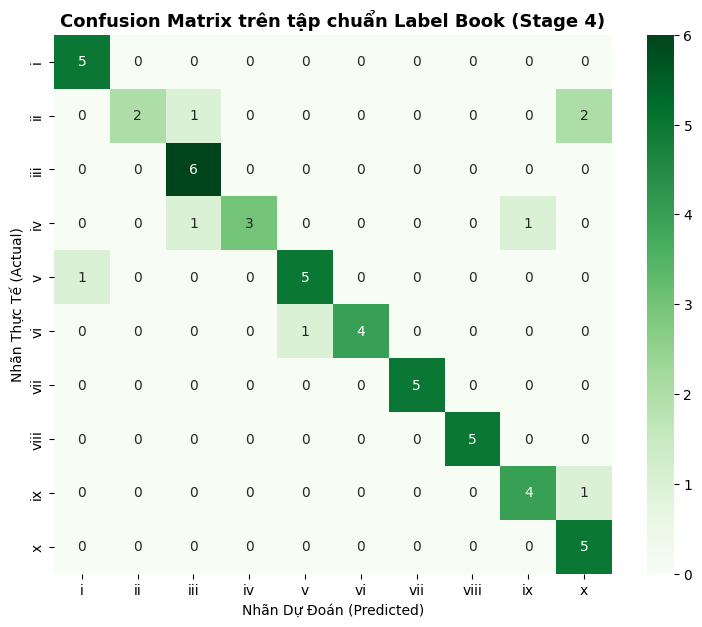

Báo cáo hiệu năng chi tiết (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

           i       0.83      1.00      0.91         5
          ii       1.00      0.40      0.57         5
         iii       0.75      1.00      0.86         6
          iv       1.00      0.60      0.75         5
           v       0.83      0.83      0.83         6
          vi       1.00      0.80      0.89         5
         vii       1.00      1.00      1.00         5
        viii       1.00      1.00      1.00         5
          ix       0.80      0.80      0.80         5
           x       0.62      1.00      0.77         5

    accuracy                           0.85        52
   macro avg       0.88      0.84      0.84        52
weighted avg       0.88      0.85      0.84        52



In [20]:
y_true = []
y_pred = []

for images, labels in clean_lb_ds:
    preds = best_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix trên tập chuẩn Label Book (Stage 4)", fontsize=13, fontweight="bold")
plt.xlabel("Nhãn Dự Đoán (Predicted)")
plt.ylabel("Nhãn Thực Tế (Actual)")
plt.show()

print("Báo cáo hiệu năng chi tiết (Precision, Recall, F1-Score):")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))


## 3. SO SÁNH ĐỦ 6 STAGE HUẤN LUYỆN: STAGE 0–5

| Stage | Validation Accuracy | Validation Loss | Label Book Accuracy | Label Book Loss |
|---|---:|---:|---:|---:|
| 0 — Baseline | 63.96% | 0.9633 | 59.62% | 1.4736 |
| 1 — Làm sạch | 53.81% | 1.4332 | 55.77% | 1.4091 |
| 2 — Chuẩn hóa hình học | 82.65% | 0.7222 | 76.92% | 0.8010 |
| 3 — Cân bằng 7.500 ảnh | 90.87% | 0.4356 | 84.62% | 0.9228 |
| 4 — Mở rộng 9.500 ảnh | 91.42% | 0.4100 | 84.62% | 0.8788 |
| 5 — Superior | 86.02% | 0.6391 | 84.62% | 0.4323 |

Bảng khớp các dòng đánh giá cuối của 6 stage; hai đường accuracy khớp biểu đồ đã lưu bên dưới. Stage 4 có validation accuracy cao nhất (**91.42%**). Stage 3, Stage 4 và Superior cùng đạt Label Book Accuracy **84.62%**; Superior có Label Book Loss thấp nhất (**0.4323**).

Validation giữa các stage khác nhau; Stage 3–4 chia sau augmentation, Superior chia ảnh nguồn trước augmentation. Label Book ở Stage 0–1 là ảnh gốc, Stage 2–4 được chuẩn hóa hình học, Superior dùng tiền xử lý High-Res rồi resize Lanczos. Đây là so sánh các pipeline, không phải ablation được kiểm soát hoàn toàn. Một ảnh đúng/sai trên 52 ảnh Label Book tương ứng khoảng **1.92 điểm phần trăm**.


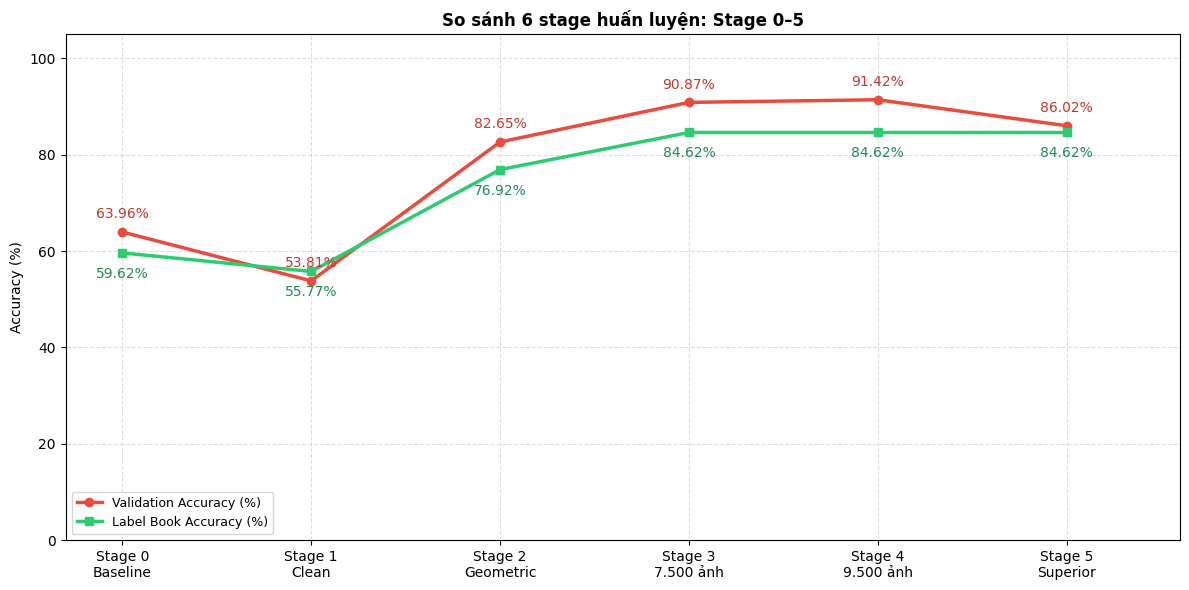

In [21]:
# So sánh đủ sáu stage; không tự điền kết quả chính xác cho Superior.
import math

stages = ["Stage 0\nBaseline", "Stage 1\nClean", "Stage 2\nGeometric",
          "Stage 3\n7.500 ảnh", "Stage 4\n9.500 ảnh", "Stage 5\nSuperior"]
val_accuracies = [round(float(globals().get(f"val_acc_s{i}", saved / 100)) * 100, 2)
                  for i, saved in enumerate([65.19, 60.18, 84.25, 90.07, 90.84])]
lb_accuracies = [round(float(globals().get(f"lb_acc_s{i}", saved / 100)) * 100, 2)
                 for i, saved in enumerate([48.08, 51.92, 71.15, 82.69, 82.69])]

# Kết quả khôi phục checkpoint hoặc kết quả Superior trong kernel hiện tại.
superior_result = globals().get("superior_recovered_metrics") or globals().get("superior_metrics")
if superior_result is None and "superior_model" in globals():
    superior_result = {"val_accuracy": globals().get("val_acc"),
                       "label_book_accuracy": globals().get("lb_acc")}
superior_result = superior_result or {}
def superior_percent(key):
    value = superior_result.get(key)
    return round(float(value) * 100, 2) if value is not None else float("nan")

val_accuracies.append(superior_percent("val_accuracy"))
lb_accuracies.append(superior_percent("label_book_accuracy"))

fig, ax = plt.subplots(figsize=(12, 6))
x = list(range(6))
ax.plot(x, val_accuracies, marker="o", linewidth=2.5, color="#e74c3c", label="Validation Accuracy (%)")
ax.plot(x, lb_accuracies, marker="s", linewidth=2.5, color="#2ecc71", label="Label Book Accuracy (%)")
for i, (v, lb) in enumerate(zip(val_accuracies, lb_accuracies)):
    if math.isfinite(v):
        ax.annotate(f"{v:.2f}%", (i, v), xytext=(0, 10), textcoords="offset points",
                    ha="center", color="#c0392b")
    if math.isfinite(lb):
        ax.annotate(f"{lb:.2f}%", (i, lb), xytext=(0, -18), textcoords="offset points",
                    ha="center", color="#218c53")
if not math.isfinite(lb_accuracies[5]):
    ax.scatter([5], [88], marker="D", s=90, facecolors="none", edgecolors="#218c53",
               label="Superior ≈88%: theo người thực hiện, chưa khôi phục log")
    ax.annotate("≈88% (chưa khôi phục log)", (5, 88), xytext=(-10, -22),
                textcoords="offset points", ha="right", color="#218c53")
if not math.isfinite(val_accuracies[5]):
    ax.text(5, 10, "Chưa khôi phục\nvalidation", ha="center", color="#777777")
ax.set_xticks(x, stages)
ax.set_xlim(-0.3, 5.6)
ax.set_ylim(0, 105)
ax.set_ylabel("Accuracy (%)")
ax.set_title("So sánh 6 stage huấn luyện: Stage 0–5", fontweight="bold")
ax.legend(loc="lower left", fontsize=9)
ax.grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()


## 4. TỔNG KẾT THEO OUTPUT ĐÃ LƯU

1. **Stage 3, Stage 4 và Superior cùng đạt Label Book Accuracy cao nhất: 84.62% (44/52 ảnh)**, so với Baseline **59.62% (31/52 ảnh)**. Chênh lệch là **+25.00 điểm phần trăm**, tương ứng thêm **13 ảnh đúng**. Đây là kết quả một lần chạy được lưu, chưa có trung bình hoặc độ lệch chuẩn qua nhiều seed.
2. Stage 1 đạt **53.81% validation / 55.77% Label Book** (loss **1.4332 / 1.4091**). Cả hai accuracy đều giảm so với Baseline. Chưa thể quy riêng mức giảm cho việc loại rò rỉ vì tập train/validation cũng thay đổi.
3. Stage 2 đạt **82.65% validation / 76.92% Label Book** (loss **0.7222 / 0.8010**). Cả hai accuracy tăng so với Stage 1; tuy nhiên bộ lọc dữ liệu nguồn cũng khác, nên chưa tách riêng được tác động của chuẩn hóa hình học.
4. Stage 3 đạt **90.87% validation / 84.62% Label Book** (loss **0.4356 / 0.9228**). Stage 4 đạt **91.42% validation / 84.62% Label Book** (loss **0.4100 / 0.8788**) sau khi khôi phục epoch **14**. Mở rộng từ 7.500 lên 9.500 ảnh không làm tăng Label Book Accuracy trong lần chạy này; Label Book Loss giảm. Cả hai stage chia sau augmentation, nên validation có thể chứa các biến thể chung ảnh nguồn với train.
5. Superior dùng **9.335 train / 565 validation**, đạt **86.02% validation / 84.62% Label Book** (loss **0.6391 / 0.4323**) sau khi khôi phục epoch **7**. Superior bằng Stage 3–4 về Label Book Accuracy và có Label Book Loss thấp nhất trong 6 stage. Validation được chia theo ảnh nguồn trước augmentation, nên cần thận trọng khi so với Stage 3–4.
6. Phần đánh giá chi tiết dùng **Stage 4**, có **44 ảnh đúng / 8 ảnh sai**; recall thấp nhất là lớp `ii` (**0.40**), tiếp theo là `iv` (**0.60**). Label Book là tập tham chiếu 52 ảnh được dùng qua nhiều thử nghiệm, không phải test ẩn của cuộc thi.
